# Does the weather change how much the bakery sells?

**Author:** Mudit Joshi

**Team question:** What drives the bakery's sales besides the weekday?

**My hypothesis:** the weather matters. On warm, dry, sunny days people buy more; on cold, rainy, grey days they buy less.

**How I test it, in short:**
1. Put each day's sales next to that day's weather.
2. Compare sales on warm vs cold days (and rainy vs dry, cloudy vs clear, windy vs calm).
3. Check a trap: warm days are summer days. Is it the warmth, or just summer?

## 1. Tools

Python libraries: `pandas` for tables, `matplotlib` for charts, `scipy` for statistics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
GROUPS = {1: "Bread", 2: "Rolls", 3: "Croissants", 4: "Confectionery", 5: "Cakes", 6: "Seasonal bread"}

## 2. Load the two tables

- **Sales:** one row per day and product group. `Umsatz` = turnover (money taken; the currency is not given).
- **Weather in Kiel:** one row per day. `Temperatur` = average temperature (°C), `Bewoelkung` = cloud cover (0 = clear sky, 8 = fully overcast), `Windgeschwindigkeit` = wind speed (m/s), `Wettercode` = a weather code that tells us about rain or snow.

In [2]:
sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
weather = pd.read_csv(BASE_URL + "wetter.csv", parse_dates=["Datum"])
print(f"Sales:   {len(sales):,} rows, {sales['Datum'].min().date()} to {sales['Datum'].max().date()}")
print(f"Weather: {len(weather):,} rows, {weather['Datum'].min().date()} to {weather['Datum'].max().date()}")
weather.head()

Sales:   9,334 rows, 2013-07-01 to 2018-07-31
Weather: 2,601 rows, 2012-01-01 to 2019-08-01


,Datum,Bewoelkung,Temperatur,Windgeschwindigkeit,Wettercode
0,2012-01-01,8.0,9.8250,14,58.0
1,2012-01-02,7.0,7.4375,12,NaN
2,2012-01-03,8.0,5.5375,18,63.0
3,2012-01-04,4.0,5.6875,19,80.0
4,2012-01-05,6.0,5.3000,23,80.0


## 3. Put sales and weather side by side

We match the two tables on the date (a *merge*). We keep **every sales row**, even if the weather for that day is missing (a *left join*).

Two quick checks that the merge worked: the number of sales rows must stay the same, and we count the days that found no weather.

In [3]:
merged = sales.merge(weather, on="Datum", how="left", indicator=True)

assert len(merged) == len(sales), "The merge must not add or lose sales rows"
assert not merged.duplicated(["Datum", "Warengruppe"]).any(), "Still one row per day and product group"

no_weather = merged.loc[merged["_merge"] == "left_only", "Datum"].dt.date.unique()
print(f"Rows before and after: {len(sales):,} = {len(merged):,}")
print(f"Sales days without weather data: {len(no_weather)} -> {list(no_weather)}")
merged = merged.drop(columns="_merge")

Rows before and after: 9,334 = 9,334
Sales days without weather data: 3 -> [datetime.date(2016, 12, 11), datetime.date(2017, 10, 4), datetime.date(2017, 10, 5)]


## 4. What is missing?

Share of empty values per column. Almost nothing is missing, except the weather code. An empty weather code most likely means *nothing special happened* (no rain, no snow), so we read it as "no rain reported".

In [4]:
merged.isna().mean().mul(100).round(1).rename("missing (%)").to_frame()

,missing (%)
id,0.0
Datum,0.0
Warengruppe,0.0
Umsatz,0.0
Bewoelkung,0.7
Temperatur,0.2
Windgeschwindigkeit,0.2
Wettercode,24.9


## 5. One number per day

The question is about the whole bakery, so we add up all product groups for each day and attach that day's weather.

In [5]:
daily = (sales.groupby("Datum", as_index=False)["Umsatz"].sum()
         .merge(weather, on="Datum", how="left")
         .dropna(subset=["Temperatur"]))
daily["month"] = daily["Datum"].dt.month
daily["year"] = daily["Datum"].dt.year
daily["weekday"] = daily["Datum"].dt.day_of_week
print(f"Days in the analysis: {len(daily):,}")
daily["Temperatur"].describe().round(1)

Days in the analysis: 1,816


count    1816.0
mean       12.2
std         7.3
min        -8.5
25%         6.4
50%        12.0
75%        18.1
max        31.4
Name: Temperatur, dtype: float64

## 6. How warm does it get in Kiel?

A histogram: how many days fall into each temperature range.

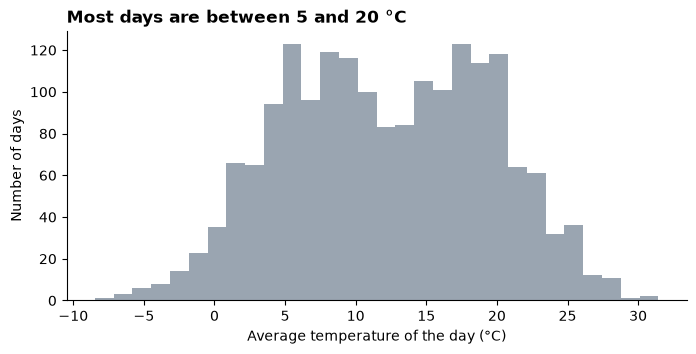

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(daily["Temperatur"], bins=30, color="#9aa5b1")
ax.set_xlabel("Average temperature of the day (°C)")
ax.set_ylabel("Number of days")
ax.set_title("Most days are between 5 and 20 °C", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 7. Do warm days sell more?

We sort the days into temperature bands (below 0 °C, 0–5 °C, …) and take the average turnover in each band.

The black lines are **95 % confidence intervals**: the range in which the true average most likely lies. Short line = we know the average well. If two lines don't overlap, the difference is real, not chance.

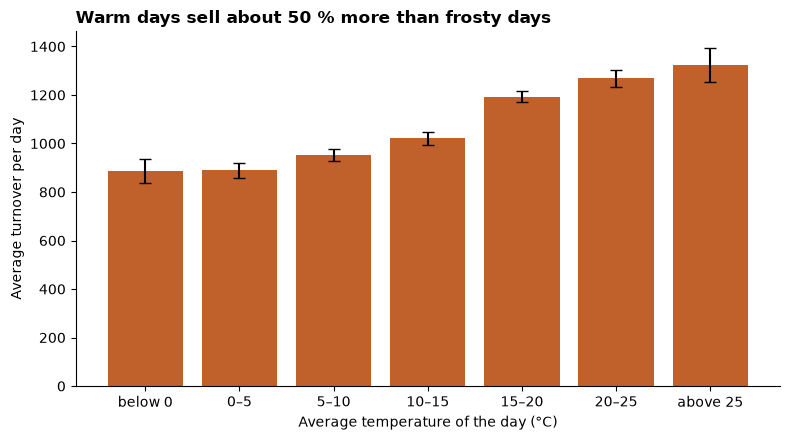

Correlation r = 0.48  (0 = no link, 1 = perfect link; 0.5 is a clear link)


,days,mean,ci_low,ci_high
temp_band,,,,
below 0,68.0,886.0,837.0,934.0
0–5,271.0,890.0,858.0,921.0
5–10,422.0,951.0,927.0,976.0
10–15,345.0,1022.0,996.0,1047.0
15–20,426.0,1193.0,1169.0,1217.0
20–25,230.0,1269.0,1234.0,1304.0
above 25,54.0,1324.0,1255.0,1393.0


In [7]:
def mean_ci(values, level=0.95):
    """Average of the values and its 95 % confidence interval."""
    values = pd.Series(values).dropna()
    n, mean = len(values), values.mean()
    half = stats.t.ppf((1 + level) / 2, n - 1) * values.std(ddof=1) / np.sqrt(n)
    return pd.Series({"days": n, "mean": mean, "ci_low": mean - half, "ci_high": mean + half})

bands = [-20, 0, 5, 10, 15, 20, 25, 40]
labels = ["below 0", "0–5", "5–10", "10–15", "15–20", "20–25", "above 25"]
daily["temp_band"] = pd.cut(daily["Temperatur"], bands, labels=labels)
by_band = daily.groupby("temp_band", observed=True)["Umsatz"].apply(mean_ci).unstack()

fig, ax = plt.subplots(figsize=(8, 4.5))
err = [by_band["mean"] - by_band["ci_low"], by_band["ci_high"] - by_band["mean"]]
ax.bar(by_band.index.astype(str), by_band["mean"], yerr=err, capsize=4, color="#c0612b")
ax.set_xlabel("Average temperature of the day (°C)")
ax.set_ylabel("Average turnover per day")
ax.set_title("Warm days sell about 50 % more than frosty days", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

r = daily[["Umsatz", "Temperatur"]].corr().iloc[0, 1]
print(f"Correlation r = {r:.2f}  (0 = no link, 1 = perfect link; 0.5 is a clear link)")
by_band.round(0)

**What this shows:** the warmer the day, the more the bakery sells, step by step. Above 25 °C it sells about 50 % more than on frosty days.

## 8. The trap: is it the warmth, or just summer?

Warm days are summer days, and summer in Kiel also brings tourists, school holidays and Kiel Week. Any of these could be the real reason.

**The trick:** compare each day only with similar days, the same weekday in the same month of the same year. For example, a warm Tuesday in May 2016 is compared with the other Tuesdays of May 2016.

- *temperature difference*: how much warmer or colder the day was than usual for that month,
- *relative turnover*: 1.00 = a normal day for that month and weekday; 1.05 = 5 % more than normal.

If warmth itself makes people buy more, the unusually warm days should sell more than normal.

In [8]:
daily["temp_diff"] = daily["Temperatur"] - daily.groupby(["year", "month"])["Temperatur"].transform("mean")
daily["rel_turnover"] = daily["Umsatz"] / daily.groupby(["year", "month", "weekday"])["Umsatz"].transform("mean")

daily["compared_to_month"] = pd.cut(daily["temp_diff"], [-30, -3, 3, 30],
                                    labels=["more than 3 °C colder", "normal (±3 °C)", "more than 3 °C warmer"])
within = daily.groupby("compared_to_month", observed=True)["rel_turnover"].apply(mean_ci).unstack()

r_within = daily[["rel_turnover", "temp_diff"]].corr().iloc[0, 1]
print(f"Correlation within the same month: r = {r_within:.2f}")
within.round(3)

Correlation within the same month: r = 0.00


,days,mean,ci_low,ci_high
compared_to_month,,,,
more than 3 °C colder,276.0,1.009,0.989,1.028
normal (±3 °C),1256.0,0.997,0.990,1.004
more than 3 °C warmer,284.0,1.004,0.987,1.021


**What this shows:** within the same month, unusually warm or cold days sell **the same** as normal days (all about 1.00, r ≈ 0). So the big difference in step 7 comes from the **season**, not from the temperature itself.

The chart below shows why: over the year, turnover and temperature rise and fall together.

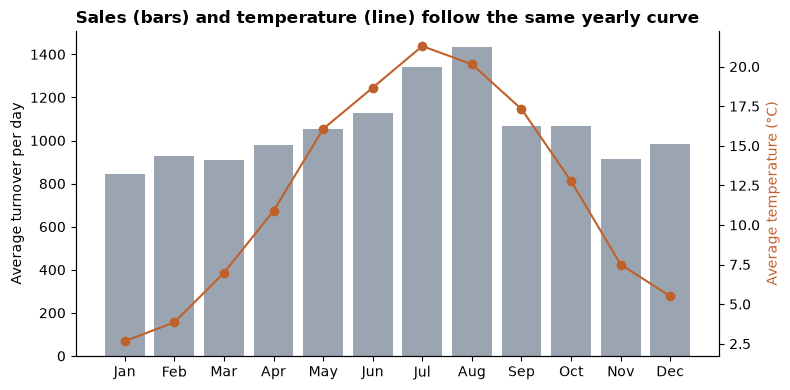

In [9]:
monthly = daily.groupby("month").agg(temperature=("Temperatur", "mean"), turnover=("Umsatz", "mean"))
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(monthly.index, monthly["turnover"], color="#9aa5b1")
ax1.set_ylabel("Average turnover per day")
ax1.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["temperature"], color="#c0612b", marker="o")
ax2.set_ylabel("Average temperature (°C)", color="#c0612b")
ax1.set_title("Sales (bars) and temperature (line) follow the same yearly curve", loc="left", fontweight="bold")
ax1.spines[["top"]].set_visible(False); ax2.spines[["top"]].set_visible(False)
fig.tight_layout()
plt.show()

## 9. Which products react to temperature?

For each product group: how strongly its sales go up with temperature (correlation r). Orange = sells more when warm, blue = sells less.

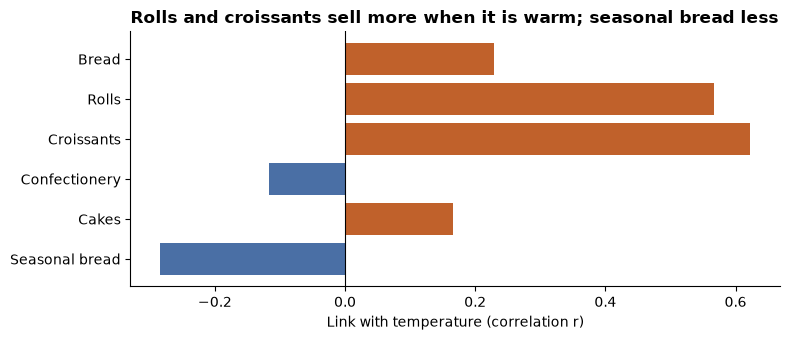

,days,r
group,,
Bread,1816,0.23
Rolls,1816,0.57
Croissants,1816,0.62
Confectionery,1763,-0.12
Cakes,1816,0.17
Seasonal bread,291,-0.28


In [10]:
rows = []
for code_, name in GROUPS.items():
    g = merged[merged["Warengruppe"] == code_].dropna(subset=["Temperatur"])
    rows.append({"group": name, "days": len(g), "r": g[["Umsatz", "Temperatur"]].corr().iloc[0, 1]})
by_group = pd.DataFrame(rows).set_index("group")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(by_group.index, by_group["r"], color=["#c0612b" if r > 0 else "#4a6fa5" for r in by_group["r"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()
ax.set_xlabel("Link with temperature (correlation r)")
ax.set_title("Rolls and croissants sell more when it is warm; seasonal bread less", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
by_group.round(2)

**What this shows:** rolls and croissants (snacks people buy on the go) follow the warm season most. Seasonal bread is only sold in winter, so it goes the other way.

## 10. Rain, clouds and wind

Same trick as in step 8, so the season can't fool us: each day compared with normal days of its month (1.00 = normal).

Rain comes from the weather code: codes 50–69 and 80–99 mean rain, drizzle or showers; 70–79 mean snow; an empty code means no rain was reported.

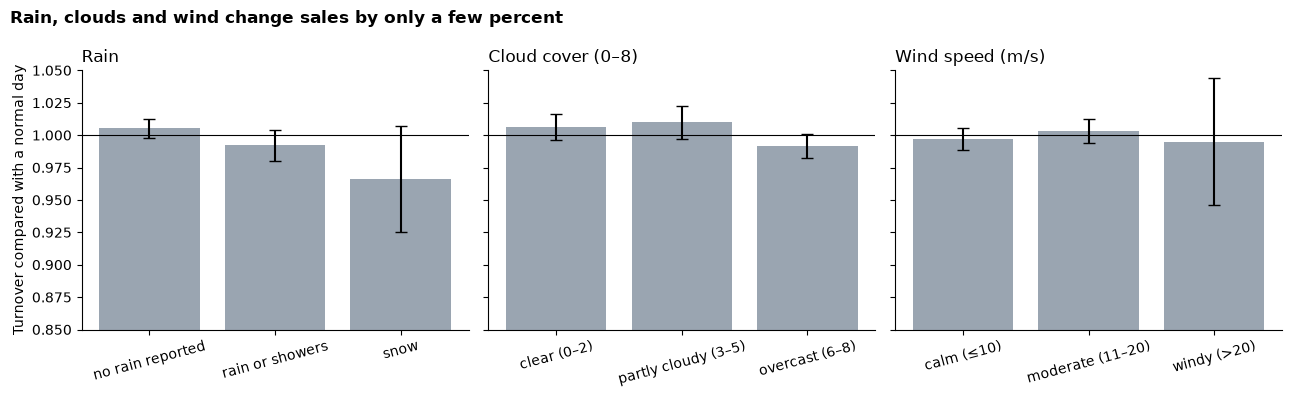

days   mean  ci_low  ci_high
Rain              no rain reported     1173.0  1.005   0.998    1.012
                  rain or showers       603.0  0.992   0.980    1.004
                  snow                   40.0  0.966   0.925    1.007
Cloud cover (0–8) clear (0–2)           451.0  1.006   0.996    1.016
                  partly cloudy (3–5)   423.0  1.010   0.997    1.023
                  overcast (6–8)        933.0  0.992   0.982    1.001
Wind speed (m/s)  calm (≤10)            959.0  0.997   0.989    1.006
                  moderate (11–20)      814.0  1.003   0.994    1.013
                  windy (>20)            43.0  0.995   0.946    1.044

In [11]:
code_ = daily["Wettercode"]
daily["rain"] = np.select([code_.between(50, 69) | code_.between(80, 99), code_.between(70, 79)],
                          ["rain or showers", "snow"], default="no rain reported")
daily["clouds"] = pd.cut(daily["Bewoelkung"], [-1, 2, 5, 8], labels=["clear (0–2)", "partly cloudy (3–5)", "overcast (6–8)"])
daily["wind"] = pd.cut(daily["Windgeschwindigkeit"], [-1, 10, 20, 60], labels=["calm (≤10)", "moderate (11–20)", "windy (>20)"])

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
tables = {}
for ax, col, title in zip(axes, ["rain", "clouds", "wind"], ["Rain", "Cloud cover (0–8)", "Wind speed (m/s)"]):
    t = daily.groupby(col, observed=True)["rel_turnover"].apply(mean_ci).unstack()
    if col == "rain":
        t = t.loc[["no rain reported", "rain or showers", "snow"]]
    tables[title] = t
    err = [t["mean"] - t["ci_low"], t["ci_high"] - t["mean"]]
    ax.bar(t.index.astype(str), t["mean"], yerr=err, capsize=4, color="#9aa5b1")
    ax.axhline(1, color="black", linewidth=0.8)
    ax.set_ylim(0.85, 1.05)
    ax.set_title(title, loc="left")
    ax.tick_params(axis="x", rotation=15)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Turnover compared with a normal day")
fig.suptitle("Rain, clouds and wind change sales by only a few percent", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()
pd.concat(tables).round(3)

**What this shows:** small effects. Rainy days sell about 1 % less than normal, snowy days about 3 % less, overcast days about 1–2 % less. Wind makes no visible difference.

## 11. Do the weather factors move together?

If two factors usually come together (for example clouds and rain), it is hard to tell which one really affects sales. This matters later, when several factors go into one model together. The table shows how strongly each pair moves together (1 = always together, 0 = unrelated, negative = opposite).

In [12]:
daily["is_rainy"] = (daily["rain"] != "no rain reported").astype(int)
factors = daily[["Temperatur", "Bewoelkung", "Windgeschwindigkeit", "is_rainy", "month"]].rename(columns={
    "Temperatur": "temperature", "Bewoelkung": "clouds", "Windgeschwindigkeit": "wind", "is_rainy": "rain"})
factors["summer"] = factors["month"].isin([6, 7, 8]).astype(int)
factors.drop(columns="month").corr().round(2)

,temperature,clouds,wind,rain,summer
temperature,1.00,-0.39,-0.00,-0.18,0.66
clouds,-0.39,1.00,0.04,0.49,-0.19
wind,-0.00,0.04,1.00,0.15,0.02
rain,-0.18,0.49,0.15,1.00,-0.06
summer,0.66,-0.19,0.02,-0.06,1.00


**What this shows:** clouds and rain go together, and temperature goes with summer. In a model we should not count the same thing twice; for example, temperature and season mostly tell the same story.

## 12. Conclusion

**Short answer:** the weather matters less than it looks.

- **Warm days sell about 50 % more than frosty days**, but that is mainly **summer**, not the warmth itself. Within the same month, warmer or colder days sell about the same.
- **Rolls and croissants** follow the warm season most; **seasonal bread** goes the other way.
- **Rain, clouds and wind** change sales by only 1–3 %.

**What this means for the forecast:** the month or season will do most of the work; the weather adds little on top. Also, the day before we only know the weather *forecast*, not the real weather.

**Limits:** these are links, not proof of cause; rain is read from a weather code, not measured amounts; daily averages hide the weather at busy shopping hours; data from one bakery in Kiel.